In [91]:
# Install libraries on the uv venv
!uv add pandas
!uv add numpy
!uv add matplotlib

Resolved 6 packages in 1ms
Checked 6 packages in 0.89ms
Resolved 6 packages in 1ms
Checked 6 packages in 0.82ms
Resolved 14 packages in 259ms
   Building ecobicis-proyecto @ file:///C:/Users/Nico/Documents/GitHub/EcoBicis_proyecto
      Built ecobicis-proyecto @ file:///C:/Users/Nico/Documents/GitHub/EcoBicis_proyecto
Prepared 1 package in 29ms
Uninstalled 1 package in 1ms
Installed 8 packages in 614ms
 + contourpy==1.4.0
 + cycler==0.12.1
 ~ ecobicis-proyecto==0.1.0 (from file:///C:/Users/Nico/Documents/GitHub/EcoBicis_proyecto)
 + fonttools==4.67.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + pillow==13.0.0
 + pyparsing==3.3.3


# EDA EcoBicis


In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Estilo de las gráficas: paleta categórica fija y ejes discretos
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "lines.markersize": 5,
})

In [93]:
def fix_twiced_numbered_station(station):
    if pd.isna(station):
        return station
    station = str(station).strip()
    if station == "":
        return None
    if "-" in station:
        station = station.split("-")[0]
    return int(float(station))


## DataFrame de los viajes (1498933 viajes, septiembre 2026)

In [94]:
viajes_ruta = r"data\viajes_ecobici.csv"
viajes_df = pd.read_csv(viajes_ruta)

viajes_df.head()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,30.0,6583322,028,31/08/2026,23:54:59,258,01/09/2026,00:00:03
1,F,33.0,4139655,030,31/08/2026,23:24:43,530,01/09/2026,00:00:04
2,O,32.0,6378079,139,31/08/2026,23:46:59,559,01/09/2026,00:00:35
3,M,35.0,6074272,365,31/08/2026,23:52:10,312,01/09/2026,00:00:44
4,M,30.0,4162376,412,31/08/2026,23:51:45,337,01/09/2026,00:00:55


In [95]:
viajes = viajes_df.copy()

In [96]:
# Horario de retiro
viajes["Fecha_Hora_Retiro"] = pd.to_datetime(
    viajes["Fecha_Retiro"] + " " + viajes["Hora_Retiro"], 
    format="%d/%m/%Y %H:%M:%S"  )


# Horario de arribo
viajes["Fecha_Hora_Arribo"] = pd.to_datetime(
    viajes["Fecha_Arribo"] + " " + viajes["Hora_Arribo"], 
    format="%d/%m/%Y %H:%M:%S"  )

In [97]:
# EStaciones
viajes["Ciclo_EstacionArribo"] = viajes["Ciclo_EstacionArribo"].apply(fix_twiced_numbered_station)
viajes = viajes.rename(columns={"Ciclo_EstacionArribo": "Ciclo_Estacion_Arribo"})
viajes["Ciclo_Estacion_Retiro"] = viajes["Ciclo_Estacion_Retiro"].apply(fix_twiced_numbered_station)

In [98]:
viajes

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_Estacion_Arribo,Fecha_Arribo,Hora_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo
0,M,30.0,6583322,28,31/08/2026,23:54:59,258,01/09/2026,00:00:03,2026-08-31 23:54:59,2026-09-01 00:00:03
1,F,33.0,4139655,30,31/08/2026,23:24:43,530,01/09/2026,00:00:04,2026-08-31 23:24:43,2026-09-01 00:00:04
2,O,32.0,6378079,139,31/08/2026,23:46:59,559,01/09/2026,00:00:35,2026-08-31 23:46:59,2026-09-01 00:00:35
3,M,35.0,6074272,365,31/08/2026,23:52:10,312,01/09/2026,00:00:44,2026-08-31 23:52:10,2026-09-01 00:00:44
4,M,30.0,4162376,412,31/08/2026,23:51:45,337,01/09/2026,00:00:55,2026-08-31 23:51:45,2026-09-01 00:00:55
...,...,...,...,...,...,...,...,...,...,...,...
1498929,M,45.0,5402276,513,30/09/2026,23:50:37,519,30/09/2026,23:59:32,2026-09-30 23:50:37,2026-09-30 23:59:32
1498930,M,37.0,4451399,41,30/09/2026,23:48:44,183,30/09/2026,23:59:32,2026-09-30 23:48:44,2026-09-30 23:59:32
1498931,M,44.0,6252977,693,30/09/2026,23:54:10,440,30/09/2026,23:59:39,2026-09-30 23:54:10,2026-09-30 23:59:39
1498932,M,33.0,3056892,57,30/09/2026,23:54:23,28,30/09/2026,23:59:54,2026-09-30 23:54:23,2026-09-30 23:59:54


In [99]:
viajes.info()

<class 'pandas.DataFrame'>
RangeIndex: 1498934 entries, 0 to 1498933
Data columns (total 11 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Genero_Usuario         1498934 non-null  str           
 1   Edad_Usuario           1498905 non-null  float64       
 2   Bici                   1498934 non-null  int64         
 3   Ciclo_Estacion_Retiro  1498934 non-null  int64         
 4   Fecha_Retiro           1498934 non-null  str           
 5   Hora_Retiro            1498934 non-null  str           
 6   Ciclo_Estacion_Arribo  1498934 non-null  int64         
 7   Fecha_Arribo           1498934 non-null  str           
 8   Hora_Arribo            1498934 non-null  str           
 9   Fecha_Hora_Retiro      1498934 non-null  datetime64[us]
 10  Fecha_Hora_Arribo      1498934 non-null  datetime64[us]
dtypes: datetime64[us](2), float64(1), int64(3), str(5)
memory usage: 125.8 MB


## DataFrame de las estaciones

In [ ]:
estaciones_ruta = r"data\estaciones_ecobici_092026.csv"
stations_df = pd.read_csv(estaciones_ruta)
stations_df.head()

,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada


In [101]:
stations = stations_df.copy()

try: stations = stations.drop(columns = ["sistema"])
except KeyError: print("sistema ya fue eliminado o no se encontró \n")

# Cambiar num_cicloe a numerico 
stations["num_cicloe"] = stations["num_cicloe"].apply(fix_twiced_numbered_station)



In [102]:
stations

,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada
3,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada
...,...,...,...,...,...,...,...,...,...
672,697,Francisco Sosa,Tres Cruces,Villa Coyoacan,Coyoacan,19.349277,-99.164921,Arroyo,Instalada
673,698,Cda. Alberto Zamora,Av. Miguel Angel de Quevedo,Villa Coyoacan,Coyoacan,19.344855,-99.163575,Arroyo,Instalada
674,699,San Gregorio,Felipe Carrillo Puerto,Villa Coyoacan,Coyoacan,19.346895,-99.163868,Arroyo,Instalada
675,441,Puente Xoco,Real de Mayorazgo,Xoco,Benito Juarez,19.361213,-99.167520,Arroyo,Instalada


In [103]:
stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 677 entries, 0 to 676
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   num_cicloe  677 non-null    int64  
 1   calle_prin  677 non-null    str    
 2   calle_secu  677 non-null    str    
 3   colonia     677 non-null    str    
 4   alcaldia    677 non-null    str    
 5   latitud     677 non-null    float64
 6   longitud    677 non-null    float64
 7   sitio_de_e  677 non-null    str    
 8   estatus     677 non-null    str    
dtypes: float64(2), int64(1), str(6)
memory usage: 47.7 KB


## Variables derivadas
Duración, fecha, hora, día de la semana, fin de semana y viajes circulares (misma estación de retiro y arribo).

In [ ]:
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

viajes["Duracion_min"] = (viajes["Fecha_Hora_Arribo"] - viajes["Fecha_Hora_Retiro"]).dt.total_seconds() / 60
viajes["Fecha"] = viajes["Fecha_Hora_Retiro"].dt.normalize() # Que día se realizó el viaje
viajes["Hora"] = viajes["Fecha_Hora_Retiro"].dt.hour   # En que hora del día se realizo este viaje 
viajes["Dia_Semana"] = viajes["Fecha_Hora_Retiro"].dt.day_of_week  # 0 = lunes
viajes["Fin_de_Semana"] = viajes["Dia_Semana"] >= 5
viajes["Viaje_Circular"] = viajes["Ciclo_Estacion_Retiro"] == viajes["Ciclo_Estacion_Arribo"]

# Las columnas de texto ya están en Fecha_Hora_Retiro / Fecha_Hora_Arribo
viajes = viajes.drop(columns=["Fecha_Retiro", "Hora_Retiro", "Fecha_Arribo", "Hora_Arribo"], errors="ignore")
viajes.head()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular
0,M,30.0,6583322,28,258,2026-08-31 23:54:59,2026-09-01 00:00:03,5.066667,2026-08-31,23,0,False,False
1,F,33.0,4139655,30,530,2026-08-31 23:24:43,2026-09-01 00:00:04,35.350000,2026-08-31,23,0,False,False
2,O,32.0,6378079,139,559,2026-08-31 23:46:59,2026-09-01 00:00:35,13.600000,2026-08-31,23,0,False,False
3,M,35.0,6074272,365,312,2026-08-31 23:52:10,2026-09-01 00:00:44,8.566667,2026-08-31,23,0,False,False
4,M,30.0,4162376,412,337,2026-08-31 23:51:45,2026-09-01 00:00:55,9.166667,2026-08-31,23,0,False,False


In [123]:
viajes.describe()

,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana
count,1.498905e+06,1.498934e+06,1.498934e+06,1.498934e+06,1498934,1498934,1.498934e+06,1498934,1.498934e+06,1.498934e+06
mean,3.480467e+01,5.488449e+06,2.969660e+02,2.948756e+02,2026-09-16 04:03:16.990429,2026-09-16 04:18:59.296536,1.570510e+01,2026-09-15 13:54:18.237119,1.365464e+01,2.653063e+00
min,1.600000e+01,2.000461e+06,1.000000e+00,1.000000e+00,2026-02-10 08:46:10,2026-09-01 00:00:03,2.666667e-01,2026-02-10 00:00:00,0.000000e+00,0.000000e+00
25%,2.800000e+01,3.742228e+06,1.170000e+02,1.140000e+02,2026-09-08 15:53:09.250000,2026-09-08 16:08:04,7.083333e+00,2026-09-08 00:00:00,1.000000e+01,1.000000e+00
50%,3.300000e+01,5.503149e+06,2.590000e+02,2.570000e+02,2026-09-16 10:13:43.500000,2026-09-16 10:28:49,1.180000e+01,2026-09-16 00:00:00,1.400000e+01,2.000000e+00
75%,4.000000e+01,7.255011e+06,4.840000e+02,4.850000e+02,2026-09-23 18:23:26.750000,2026-09-23 18:40:46,1.976667e+01,2026-09-23 00:00:00,1.700000e+01,4.000000e+00
max,9.800000e+01,8.999708e+06,7.110000e+02,7.110000e+02,2026-09-30 23:56:06,2026-09-30 23:59:57,3.040172e+05,2026-09-30 00:00:00,2.300000e+01,6.000000e+00
std,9.942483e+00,2.029211e+06,2.084627e+02,2.097202e+02,NaN,NaN,3.127859e+02,NaN,4.666441e+00,1.868629e+00


## Calidad de los datos

In [130]:
dur = viajes["Duracion_min"]

print("=" * 42)
print("Nulos por columna:")
print(viajes.isna().sum()[lambda s: s > 0]) # TODOS LOS NULOS EN EL DF
print("=" * 42)

print("Filas duplicadas:", viajes.duplicated().sum())
print("Géneros:", viajes["Genero_Usuario"].value_counts().to_dict())

print(f"Duración < 1 min: {(dur < 1).sum():>6}")
print(f"Duración > 3 h:   {(dur > 180).sum():>6}")
print(f"Duración > 24 h:  {(dur > 1440).sum():>6}   (max: {dur.max() / 1440:.0f} días)")
print(f"Retiros antes de septiembre: {(viajes['Fecha_Hora_Retiro'] < '2026-09-01').sum()}")

Nulos por columna:
Edad_Usuario    29
dtype: int64
Filas duplicadas: 0
Géneros: {'M': 1016851, 'F': 416346, '?': 38763, 'O': 26974}
Duración < 1 min:    215
Duración > 3 h:      538
Duración > 24 h:      31   (max: 211 días)
Retiros antes de septiembre: 101


In [ ]:
ids_catalogo = set(stations["num_cicloe"])
ids_viajes = set(viajes["Ciclo_Estacion_Retiro"]) | set(viajes["Ciclo_Estacion_Arribo"])

print("Estaciones en viajes que no están en el catálogo:", sorted(ids_viajes - ids_catalogo))
print("Estaciones (num) del catálogo sin ningún viaje:", sorted(ids_catalogo - ids_viajes))

# El CSV de estaciones trae ñ y acentos perdidos, guardados como "�"
cols_texto = ["calle_prin", "calle_secu", "colonia", "alcaldia", "sitio_de_e"]
con_error = stations[cols_texto].apply(lambda col: col.str.contains("�", regex=False)).any(axis=1)
print("Filas del catálogo con caracteres perdidos (�):", con_error.sum())
stations.loc[con_error, cols_texto].head()

Estaciones en viajes que no están en el catálogo: []
Estaciones del catálogo sin ningún viaje: [699]
Filas del catálogo con caracteres perdidos (�): 34


,calle_prin,calle_secu,colonia,alcaldia,sitio_de_e
14,Avenida Fernando,La Coru�a,Alamos,Benito Juarez,Arroyo
17,Simon Bolivar,La Coru�a,Alamos,Benito Juarez,Arroyo
63,Fresno,Eje 2 Norte Eulalia Guzm�n,Atlampa,Cuauhtemoc,Arroyo
65,Naranjo,Av. Ricardo Flores Mag�n,Atlampa,Cuauhtemoc,Arroyo
72,Av. Paseo de la Reforma,Mahatma Gandhi,Bosque de Chapultepec,Miguel Hidalgo,Camell�n


**Hallazgos**
- 31 viajes duran más de 24 h (el más largo ~211 días, con retiros desde febrero): bicis no devueltas o errores de registro.
- 215 viajes duran menos de 1 min: probablemente retiros cancelados.
- 38,763 viajes tienen género `?` (sin dato) y 29 no tienen edad.
- Todas las estaciones de los viajes existen en el catálogo; la 699 no tiene viajes en septiembre.
- 34 estaciones tienen ñ/acentos perdidos (`La Coru�a`). El `�` ya viene en el archivo, así que no se recupera leyendo con otro encoding.

Para el resto del análisis se usan los viajes retirados en septiembre con duración entre 1 min y 3 h.

### Viajes validos df

In [166]:
# Viajes validos (menores a 3 horas, emepzando desde 1 sept)
viajes_validos = viajes[
    viajes["Duracion_min"].between(1, 180) & (viajes["Fecha_Hora_Retiro"] >= "2026-09-01")
].copy()
print("Viajes validos:")
print(f"{len(viajes_validos):,} de {len(viajes):,} viajes ({len(viajes_validos) / len(viajes):.2%})")

viajes_validos.head()

Viajes validos:
1,498,099 de 1,498,934 viajes (99.94%)


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular
19,M,41.0,7483787,7,261,2026-09-01 00:00:28,2026-09-01 00:03:08,2.666667,2026-09-01,0,1,False,False
35,M,51.0,5717525,632,641,2026-09-01 00:01:38,2026-09-01 00:04:55,3.283333,2026-09-01,0,1,False,False
41,M,26.0,6196315,340,323,2026-09-01 00:02:24,2026-09-01 00:06:11,3.783333,2026-09-01,0,1,False,False
45,O,31.0,4826665,359,357,2026-09-01 00:03:46,2026-09-01 00:06:41,2.916667,2026-09-01,0,1,False,False
48,M,39.0,6283766,577,280,2026-09-01 00:00:20,2026-09-01 00:06:50,6.500000,2026-09-01,0,1,False,False


## Perfil de usuarios

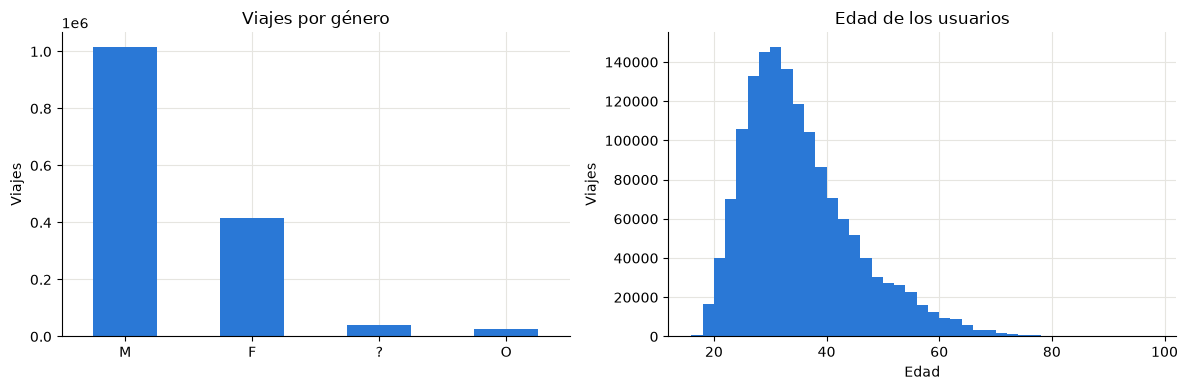

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Genero_Usuario"].value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Viajes por género", xlabel="", ylabel="Viajes")

viajes_validos["Edad_Usuario"].plot.hist(bins=range(16, 100, 2), ax=axes[1])
axes[1].set(title="Edad de los usuarios", xlabel="Edad", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [109]:
rango_edad = pd.cut(
    viajes_validos["Edad_Usuario"],
    bins=[15, 24, 34, 44, 54, 64, 100],
    labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
# Proporción de cada rango de edad dentro de cada género
pd.crosstab(rango_edad, viajes_validos["Genero_Usuario"], normalize="columns").round(3)

Genero_Usuario,?,F,M,O
Edad_Usuario,,,,
16-24,0.163,0.124,0.114,0.092
25-34,0.548,0.508,0.429,0.496
35-44,0.209,0.243,0.282,0.311
45-54,0.056,0.088,0.117,0.078
55-64,0.021,0.031,0.046,0.020
65+,0.003,0.006,0.012,0.002


## Patrones temporales
Los promedios se dividen entre el número de días de cada tipo (septiembre 2026 tiene 22 días entre semana y 8 de fin de semana).

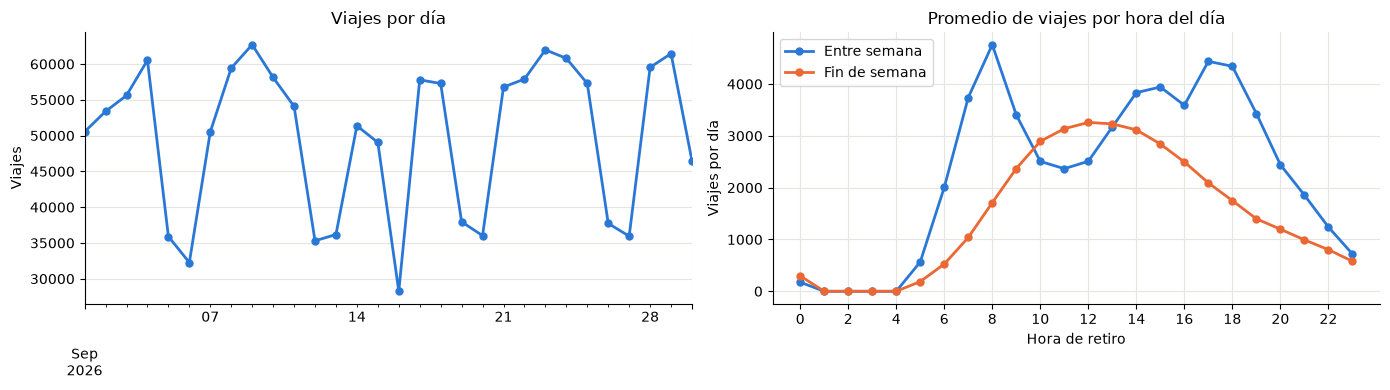

In [110]:
dias_por_tipo = viajes_validos.groupby("Fin_de_Semana")["Fecha"].nunique()
# Ecobici no opera de 1:00 a 4:59, así que esas horas se rellenan con 0
por_hora = viajes_validos.groupby(["Hora", "Fin_de_Semana"]).size().unstack().reindex(range(24), fill_value=0) / dias_por_tipo
por_hora.columns = ["Entre semana", "Fin de semana"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

viajes_validos.groupby("Fecha").size().plot(ax=axes[0], marker="o")
axes[0].set(title="Viajes por día", xlabel="", ylabel="Viajes")

por_hora.plot(ax=axes[1], marker="o")
axes[1].set(title="Promedio de viajes por hora del día", xlabel="Hora de retiro", ylabel="Viajes por día")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

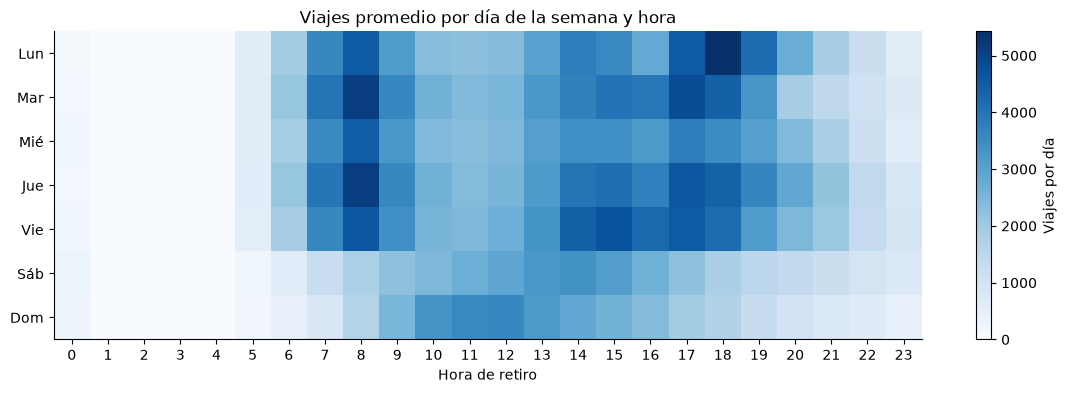

In [111]:
dias_por_semana = viajes_validos.groupby("Dia_Semana")["Fecha"].nunique()
calor = (pd.crosstab(viajes_validos["Dia_Semana"], viajes_validos["Hora"])
         .reindex(columns=range(24), fill_value=0)
         .div(dias_por_semana, axis=0))

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(calor, cmap="Blues", aspect="auto")
ax.set_yticks(range(7), DIAS)
ax.set_xticks(range(24))
ax.grid(False)
ax.set(title="Viajes promedio por día de la semana y hora", xlabel="Hora de retiro")
fig.colorbar(im, ax=ax, label="Viajes por día")
plt.show()

## Duración de los viajes

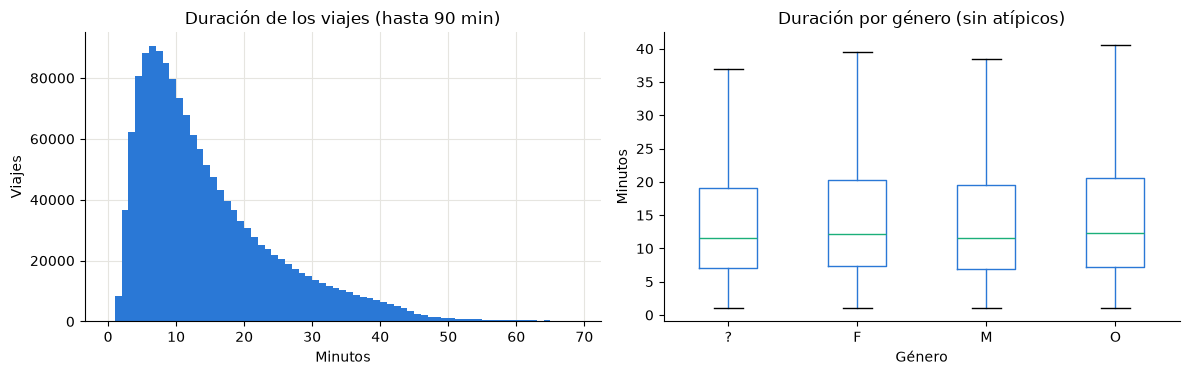

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Duracion_min"].plot.hist(bins=range(0, 70), ax=axes[0])
axes[0].set(title="Duración de los viajes (hasta 90 min)", xlabel="Minutos", ylabel="Viajes")

viajes_validos.boxplot(column="Duracion_min", by="Genero_Usuario", ax=axes[1], showfliers=False, grid=False)
axes[1].set(title="Duración por género (sin atípicos)", xlabel="Género", ylabel="Minutos")
fig.suptitle("")

plt.tight_layout()
plt.show()

In [113]:
(viajes_validos.groupby("Fin_de_Semana")["Duracion_min"]
    .describe(percentiles=[0.5, 0.9]).round(1)
    .rename(index={False: "Entre semana", True: "Fin de semana"}))

,count,mean,std,min,50%,90%,max
Fin_de_Semana,,,,,,,
Entre semana,1210795.0,14.6,10.7,1.0,11.6,28.9,179.5
Fin de semana,287304.0,17.0,13.9,1.0,12.9,34.9,178.2


## Estaciones
`Neto` = arribos − retiros. Negativo: la estación se vacía; positivo: se llena (candidatas a rebalanceo).

In [ ]:
nombre_estacion = (stations["calle_prin"] + " y " + stations["calle_secu"]).set_axis(stations["num_cicloe"])

uso = pd.DataFrame({
    "Retiros": viajes_validos["Ciclo_Estacion_Retiro"].value_counts(),
    "Arribos": viajes_validos["Ciclo_Estacion_Arribo"].value_counts(),
}).fillna(0).astype(int)
uso.index.name = "num_cicloe"
uso["Total"] = uso["Retiros"] + uso["Arribos"]
uso["Neto"] = uso["Arribos"] - uso["Retiros"]
uso.insert(0, "Estacion", nombre_estacion)

print(f"Viajes circulares (misma estación): {viajes_validos['Viaje_Circular'].mean():.2%}")
uso.sort_values("Total", ascending=False).head(10)


Viajes circulares (misma estación): 2.75%


,Estacion,Retiros,Arribos,Total,Neto
num_cicloe,,,,,
271,Jesus Garcia y Carlos J. Meneses,11259,14805,26064,3546
548,Doctor Mariano Azuela y Jose Antonio Alzate,8870,9946,18816,1076
27,Av. Paseo de la Reforma y Havre,7715,8160,15875,445
38,Cozumel y Puebla,7788,7801,15589,13
64,Sonora y Amsterdam,6867,7679,14546,812
208,Hesiodo y Lamartine,7385,6709,14094,-676
555,Av. Ribera de San Cosme y Av. Insurgentes Centro,7080,6733,13813,-347
14,Av. Paseo de la Reforma y Rio de la Plata,6153,7290,13443,1137
43,Juarez y Doctor Mora,6333,7084,13417,751


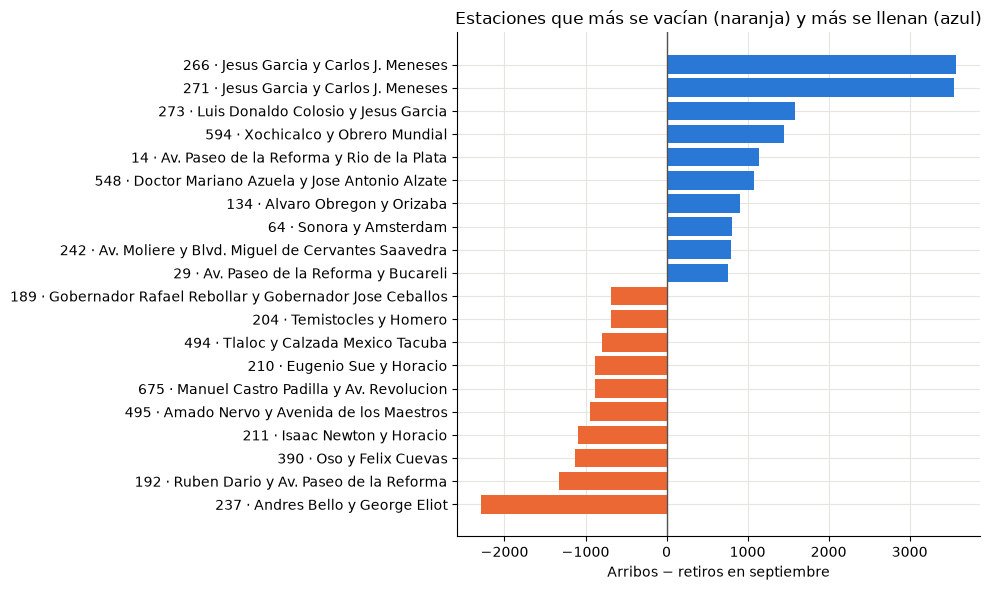

In [115]:
extremos = pd.concat([uso.nsmallest(10, "Neto"), uso.nlargest(10, "Neto")]).sort_values("Neto")
etiquetas = [f"{i} · {n}" for i, n in zip(extremos.index, extremos["Estacion"])]
colores = np.where(extremos["Neto"] < 0, "#eb6834", "#2a78d6")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(etiquetas, extremos["Neto"], color=colores)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Estaciones que más se vacían (naranja) y más se llenan (azul)", xlabel="Arribos − retiros en septiembre")
plt.tight_layout()
plt.show()

In [116]:
rutas = (
    viajes_validos[~viajes_validos["Viaje_Circular"]]
    .groupby(["Ciclo_Estacion_Retiro", "Ciclo_Estacion_Arribo"]).size()
    .nlargest(15).rename("Viajes").reset_index()
)
rutas["Origen"] = rutas["Ciclo_Estacion_Retiro"].map(nombre_estacion)
rutas["Destino"] = rutas["Ciclo_Estacion_Arribo"].map(nombre_estacion)
rutas

,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Viajes,Origen,Destino
0,621,618,811,Lago Poniente y Calzada de Tlalpan,Bartolome R. Salido y Edzna
1,548,498,607,Doctor Mariano Azuela y Jose Antonio Alzate,Avenida de los Maestros y Plan de Agua Prieta
2,618,621,598,Bartolome R. Salido y Edzna,Lago Poniente y Calzada de Tlalpan
3,494,486,595,Tlaloc y Calzada Mexico Tacuba,Izcoatl y Circuito Interior Melchor Ocampo
4,495,499,575,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Calzada de los Gallos
5,237,235,560,Andres Bello y George Eliot,Campos Eliseos y Av. Moliere
6,495,498,513,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Plan de Agua Prieta
7,593,595,498,Zempoala y Diagonal de San Antonio,Yacatas y Diagonal de San Antonio
8,538,548,458,Eligio Ancona y Circuito Interior Instituto Te...,Doctor Mariano Azuela y Jose Antonio Alzate
9,539,548,455,Naranjo y Av. Ricardo Flores Mag�n,Doctor Mariano Azuela y Jose Antonio Alzate


## Análisis geográfico
La distancia es en línea recta entre estaciones (cota inferior de la distancia real recorrida).

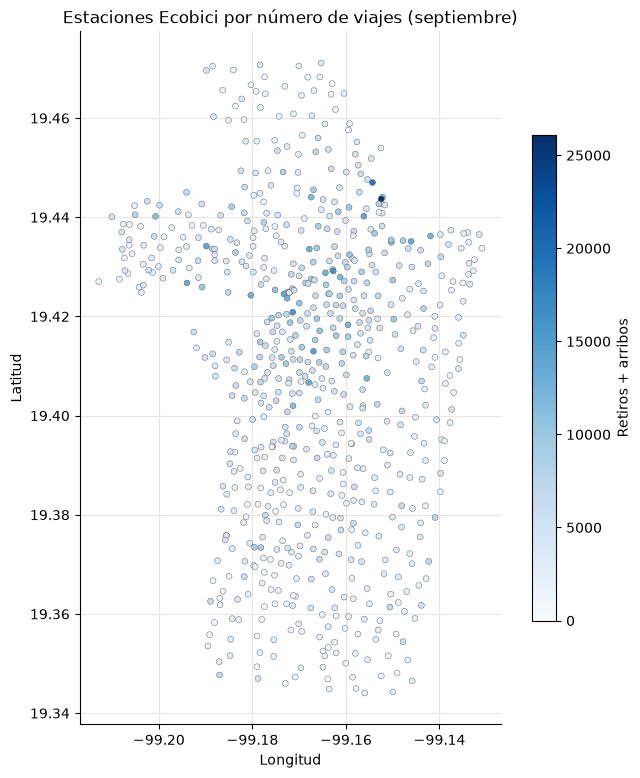

In [141]:
coords = stations.set_index("num_cicloe")
mapa = coords.join(uso["Total"]).fillna({"Total": 0})

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(mapa["longitud"], mapa["latitud"], c=mapa["Total"], cmap="Blues",
                s=18, edgecolors="#52514e", linewidths=0.3)
ax.set_aspect(1 / np.cos(np.radians(mapa["latitud"].mean())))
ax.set(title="Estaciones Ecobici por número de viajes (septiembre)", xlabel="Longitud", ylabel="Latitud")
fig.colorbar(sc, ax=ax, label="Retiros + arribos", shrink=0.7)
plt.show()

# TODO: Add the street map

#### Domingo: Analisis geografico

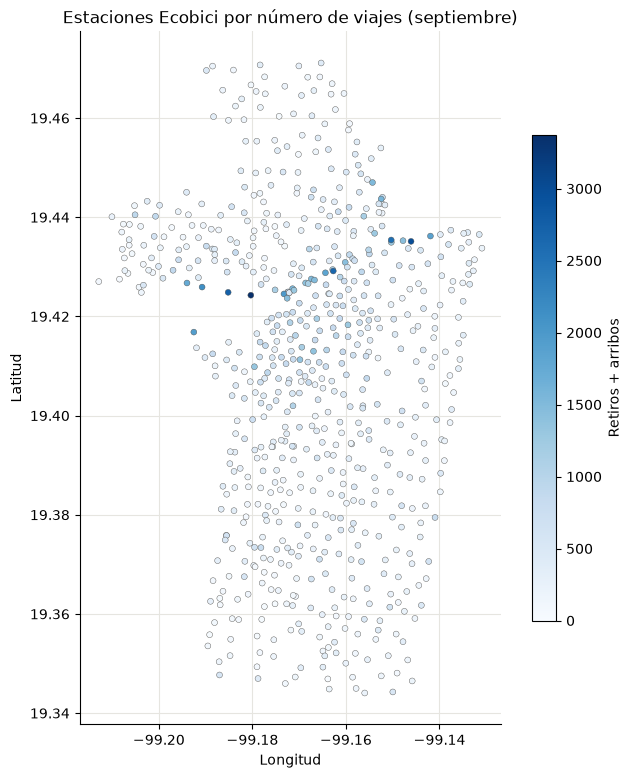

In [171]:
viajes_validos_dom = viajes_validos.iloc[viajes_validos["Dia_Semana"] == 6]

uso_dom = pd.DataFrame({
    "Retiros": viajes_validos_dom["Ciclo_Estacion_Retiro"].value_counts(),
    "Arribos": viajes_validos_dom["Ciclo_Estacion_Arribo"].value_counts(),
}).fillna(0).astype(int)
uso_dom.index.name = "num_cicloe"
uso_dom["Total"] = uso_dom["Retiros"] + uso_dom["Arribos"]
uso_dom["Neto"] = uso_dom["Arribos"] - uso_dom["Retiros"]
uso_dom.insert(0, "Estacion", nombre_estacion)

coords = stations.set_index("num_cicloe")
mapa_dom = coords.join(uso_dom["Total"]).fillna({"Total": 0})

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(mapa_dom["longitud"], mapa_dom["latitud"], c=mapa_dom["Total"], cmap="Blues",
                s=18, edgecolors="#52514e", linewidths=0.3)
ax.set_aspect(1 / np.cos(np.radians(mapa_dom["latitud"].mean())))
ax.set(title="Estaciones Ecobici por número de viajes (septiembre)", xlabel="Longitud", ylabel="Latitud")
fig.colorbar(sc, ax=ax, label="Retiros + arribos", shrink=0.7)
plt.show()

# TODO: Add the street map

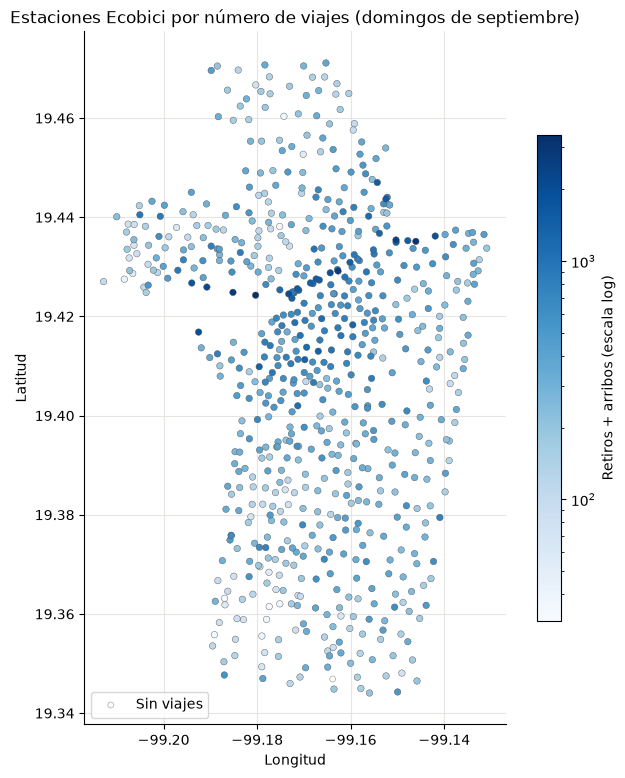

In [172]:
from matplotlib.colors import LogNorm

viajes_validos_dom = viajes_validos[viajes_validos["Dia_Semana"] == 6]

uso_dom = pd.DataFrame({
    "Retiros": viajes_validos_dom["Ciclo_Estacion_Retiro"].value_counts(),
    "Arribos": viajes_validos_dom["Ciclo_Estacion_Arribo"].value_counts(),
}).fillna(0).astype(int)
uso_dom.index.name = "num_cicloe"
uso_dom["Total"] = uso_dom["Retiros"] + uso_dom["Arribos"]
uso_dom["Neto"] = uso_dom["Arribos"] - uso_dom["Retiros"]
uso_dom.insert(0, "Estacion", nombre_estacion)

coords = stations.set_index("num_cicloe")
mapa_dom = coords.join(uso_dom["Total"]).fillna({"Total": 0})

sin_viajes = mapa_dom[mapa_dom["Total"] == 0]
con_viajes = mapa_dom[mapa_dom["Total"] > 0].sort_values("Total")  # las más usadas se dibujan encima

fig, ax = plt.subplots(figsize=(8, 9))

# Estaciones sin viajes: círculo gris vacío
ax.scatter(sin_viajes["longitud"], sin_viajes["latitud"], s=18,
           facecolors="none", edgecolors="#b5b4ae", linewidths=0.6, label="Sin viajes")

# Estaciones con viajes: escala logarítmica
sc = ax.scatter(con_viajes["longitud"], con_viajes["latitud"], c=con_viajes["Total"],
                cmap="Blues", norm=LogNorm(vmin=con_viajes["Total"].min(), vmax=con_viajes["Total"].max()),
                s=22, edgecolors="#52514e", linewidths=0.3)

ax.set_aspect(1 / np.cos(np.radians(mapa_dom["latitud"].mean())))
ax.set(title="Estaciones Ecobici por número de viajes (domingos de septiembre)", xlabel="Longitud", ylabel="Latitud")
fig.colorbar(sc, ax=ax, label="Retiros + arribos (escala log)", shrink=0.7)
if len(sin_viajes):
    ax.legend(loc="lower left")
plt.show()


In [118]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


origen = coords.loc[viajes_validos["Ciclo_Estacion_Retiro"], ["latitud", "longitud"]].to_numpy()
destino = coords.loc[viajes_validos["Ciclo_Estacion_Arribo"], ["latitud", "longitud"]].to_numpy()

viajes_validos["Distancia_km"] = haversine_km(origen[:, 0], origen[:, 1], destino[:, 0], destino[:, 1])
viajes_validos["Velocidad_kmh"] = viajes_validos["Distancia_km"] / (viajes_validos["Duracion_min"] / 60)

no_circulares = viajes_validos[~viajes_validos["Viaje_Circular"]]
print(f"Viajes a más de 30 km/h (sospechosos): {(no_circulares['Velocidad_kmh'] > 30).sum()}")
no_circulares[["Distancia_km", "Velocidad_kmh"]].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(2)

Viajes a más de 30 km/h (sospechosos): 0


,Distancia_km,Velocidad_kmh
count,1456919.00,1456919.00
mean,1.91,8.45
std,1.39,2.93
min,0.00,0.00
5%,0.44,2.94
50%,1.50,8.61
95%,4.73,13.00
99%,6.56,15.10
max,12.60,26.28


In [165]:
cabron = no_circulares.loc[(no_circulares['Velocidad_kmh'] >= 20)].copy()
cabron = cabron.sort_values(by='Velocidad_kmh')
cabron

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Distancia_km,Velocidad_kmh
574493,M,33.0,2718344,271,270,2026-09-12 07:05:18,2026-09-12 07:07:39,2.350000,2026-09-12,7,5,True,False,0.783347,20.000340
1118024,M,34.0,5383468,390,398,2026-09-23 17:28:35,2026-09-23 17:32:36,4.016667,2026-09-23,17,2,False,False,1.338955,20.000981
1017825,M,29.0,3068541,456,86,2026-09-21 22:02:54,2026-09-21 22:18:27,15.550000,2026-09-21,22,0,False,False,5.185403,20.007986
461222,M,27.0,2153674,29,320,2026-09-10 00:06:05,2026-09-10 00:20:54,14.816667,2026-09-10,0,3,False,False,4.942721,20.015518
695778,M,26.0,8577256,421,29,2026-09-14 22:43:19,2026-09-14 23:06:58,23.650000,2026-09-14,22,0,False,False,7.890145,20.017281
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1189256,M,32.0,5893169,588,708,2026-09-24 19:05:11,2026-09-24 19:20:52,15.683333,2026-09-24,19,3,False,False,6.151720,23.534742
1008728,M,32.0,5083266,588,708,2026-09-21 19:06:40,2026-09-21 19:22:11,15.516667,2026-09-21,19,0,False,False,6.151720,23.787532
830090,M,33.0,6696785,494,487,2026-09-17 22:42:22,2026-09-17 22:43:37,1.250000,2026-09-17,22,3,False,False,0.503703,24.177736
820147,M,32.0,7361553,588,708,2026-09-17 19:05:24,2026-09-17 19:19:43,14.316667,2026-09-17,19,3,False,False,6.151720,25.781365


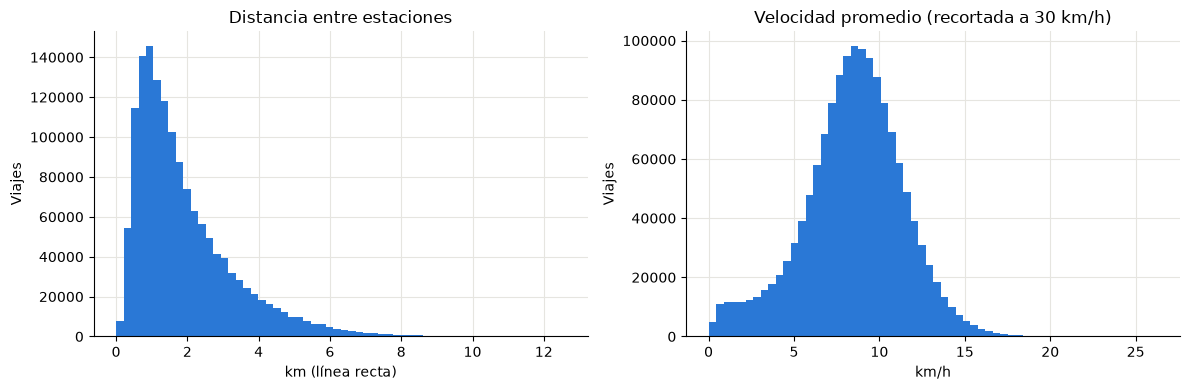

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

no_circulares["Distancia_km"].plot.hist(bins=60, ax=axes[0])
axes[0].set(title="Distancia entre estaciones", xlabel="km (línea recta)", ylabel="Viajes")

no_circulares["Velocidad_kmh"].clip(upper=30).plot.hist(bins=60, ax=axes[1])
axes[1].set(title="Velocidad promedio (recortada a 30 km/h)", xlabel="km/h", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [120]:
alcaldia = coords["alcaldia"]

por_alcaldia = pd.DataFrame({
    "Estaciones": stations["alcaldia"].value_counts(),
    "Retiros": viajes_validos["Ciclo_Estacion_Retiro"].map(alcaldia).value_counts(),
})
por_alcaldia["Retiros_por_estacion"] = (por_alcaldia["Retiros"] / por_alcaldia["Estaciones"]).round(0)
por_alcaldia.sort_values("Retiros", ascending=False)

,Estaciones,Retiros,Retiros_por_estacion
Cuauhtemoc,243,722826,2975.0
Benito Juarez,213,367118,1724.0
Miguel Hidalgo,139,320083,2303.0
Coyoacan,37,37137,1004.0
Azcapotzalco,28,29987,1071.0
Alvaro Obregon,17,20948,1232.0


In [121]:
# Proporción de destinos para cada alcaldía de origen
pd.crosstab(
    viajes_validos["Ciclo_Estacion_Retiro"].map(alcaldia).rename("Origen"),
    viajes_validos["Ciclo_Estacion_Arribo"].map(alcaldia).rename("Destino"),
    normalize="index",
).round(3)

Destino,Alvaro Obregon,Azcapotzalco,Benito Juarez,Coyoacan,Cuauhtemoc,Miguel Hidalgo
Origen,,,,,,
Alvaro Obregon,0.335,0.000,0.389,0.167,0.088,0.022
Azcapotzalco,0.000,0.471,0.005,0.000,0.181,0.343
Benito Juarez,0.020,0.000,0.744,0.038,0.157,0.040
Coyoacan,0.068,0.000,0.325,0.564,0.034,0.009
Cuauhtemoc,0.001,0.008,0.070,0.002,0.794,0.126
Miguel Hidalgo,0.001,0.035,0.048,0.001,0.346,0.569


## Uso de las bicicletas

Bicis distintas en septiembre: 6,573


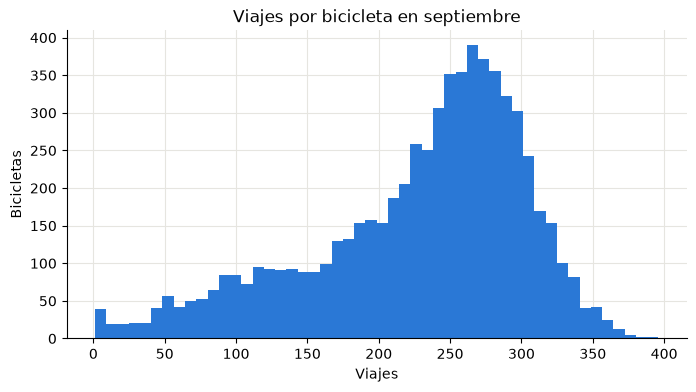

count    6573.0
mean      227.9
std        75.5
min         1.0
25%       186.0
50%       246.0
75%       282.0
max       396.0
Name: count, dtype: float64

In [122]:
viajes_por_bici = viajes_validos["Bici"].value_counts()
print(f"Bicis distintas en septiembre: {viajes_por_bici.size:,}")

fig, ax = plt.subplots(figsize=(8, 4))
viajes_por_bici.plot.hist(bins=50, ax=ax)
ax.set(title="Viajes por bicicleta en septiembre", xlabel="Viajes", ylabel="Bicicletas")
plt.show()

viajes_por_bici.describe().round(1)